# QFT recap, phase estimation and BB84

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Broum/UKP_IQC_materials/blob/main/06_Qiskit_QPE_BB84.ipynb)

Content:
* Recap: the QFT and two ways of writing a number
* Quantum phase estimation (QPE)
  * an exact phase
  * a spin in a magnetic field: an eigenstate, and a state close to it
  * a phase that does not fit into the register
* BB84 quantum key distribution
  * the protocol on the example from the textbook
  * an eavesdropper and a noisy channel
  * why the eavesdropper cannot copy the qubits

**How to use this notebook.** As in 05: a cell after **Your turn** says what we want and leaves the rest to you, with a collapsed
solution below it. Nothing later depends on your cell. The figures are drawn by helper functions from the collapsed cell in
section 0. You do not have to read it, every figure is a single line such as `show_bases(3)`.


## 0. Setup

In Colab uncomment and run the first cell after every runtime restart. Then run the two cells below it, the second one
holds the plotting helpers and is collapsed.

In [ ]:
# %pip install -q qiskit qiskit-aer pylatexenc matplotlib

In [ ]:
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector, partial_trace, state_fidelity
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

print(qiskit.__version__)

shots = 4096
sim = AerSimulator()
rng = np.random.default_rng()


def run(qc: QuantumCircuit, shots: int = shots) -> dict:
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()


def qft(n: int) -> QuantumCircuit:
    # The QFT from 05, 4.3: q_m has weight 2^m
    qc = QuantumCircuit(n, name='QFT')
    for target in reversed(range(n)):
        qc.h(target)
        for control in reversed(range(target)):
            qc.cp(np.pi / 2**(target - control), control, target)
    for i in range(n // 2):
        qc.swap(i, n - i - 1)
    return qc

2.1.2


In [ ]:
#@title Plotting helpers (run it, no need to read it)
from matplotlib.patches import Rectangle


def _clean(ax):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)


def plot_wheels(amps, row_labels=None, col_labels=None, title=None, ax=None):
    # One wheel per complex number: disc size = modulus, hand and colour = phase
    amps = np.atleast_2d(amps)
    rows, cols = amps.shape
    if ax is None:
        _, ax = plt.subplots(figsize=(0.6 * cols + 1, 0.6 * rows + 1))
    largest = np.abs(amps).max()
    for r in range(rows):
        for c in range(cols):
            a = amps[r, c] / largest * 0.42
            phase = np.angle(a) % (2 * np.pi)
            ax.add_patch(plt.Circle((c, -r), 0.42, fill=False, color='0.8', linewidth=1))
            if abs(a) > 1e-6:
                ax.add_patch(plt.Circle((c, -r), abs(a), color=plt.cm.twilight(phase / (2 * np.pi))))
                hand = 'white' if np.pi / 2 < phase < 3 * np.pi / 2 else 'black'
                ax.plot([c, c + a.real], [-r, -r + a.imag], color=hand, linewidth=1.5, solid_capstyle='round')
    ax.set_xlim(-0.55, cols - 0.45)
    ax.set_ylim(-rows + 0.45, 0.55)
    ax.set_aspect('equal')
    ax.set_xticks(range(cols), col_labels if col_labels is not None else [''] * cols)
    ax.set_yticks([-r for r in range(rows)], row_labels if row_labels is not None else [''] * rows)
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    if title:
        ax.set_title(title)
    return ax


def bloch_positions(state: Statevector) -> np.ndarray:
    # x + iy of the Bloch vector of every qubit; on the equator this is e^{i angle}
    n = state.num_qubits
    return np.array([2 * partial_trace(state, [o for o in range(n) if o != q]).data[1, 0] for q in range(n)])


def _turns(x: float) -> str:
    f = Fraction(x % 1).limit_denominator(100)
    return '0' if f == 0 else f'{f.numerator}/{f.denominator}'


def show_bases(n: int = 3):
    # Every j in the computational basis (poles) and in the Fourier basis (angles on the equator)
    bits, fourier = [], []
    for j in range(2**n):
        qc = QuantumCircuit(n)
        for q in range(n):
            if (j >> q) & 1:
                qc.x(q)
        bits.append([-1j if (j >> q) & 1 else 1j for q in reversed(range(n))])
        qc.compose(qft(n), inplace=True)
        fourier.append(bloch_positions(Statevector(qc))[::-1])
    qubit_labels = [f'$q_{q}$' for q in reversed(range(n))]
    fig, (ax_b, ax_f) = plt.subplots(1, 2, figsize=(7, 0.8 * 2**n))
    plot_wheels(bits, [f'{j} = {j:0{n}b}' for j in range(2**n)], qubit_labels,
                title='computational basis $|j\\rangle$\nhand up = 0, down = 1', ax=ax_b)
    plot_wheels(fourier, [rf'$|\tilde{{{j}}}\rangle$' for j in range(2**n)], qubit_labels,
                title='Fourier basis $|\\tilde j\\rangle$\nangles on the equator', ax=ax_f)
    plt.tight_layout()
    plt.show()


def show_qpe_stages(phi: float, t: int):
    # Control register of QPE for U = P(2 pi phi) on |1>: after H, after the controlled powers, after QFT^dagger
    qc = QuantumCircuit(t + 1)
    qc.x(t)
    qc.h(range(t))
    after_h = bloch_positions(Statevector(qc))[:t][::-1]
    for m in range(t):
        qc.cp(2 * np.pi * phi * 2**m, m, t)
    after_kick = bloch_positions(Statevector(qc))[:t][::-1]
    qc.compose(qft(t).inverse(), range(t), inplace=True)
    probs = Statevector(qc).probabilities(range(t))

    fig, axes = plt.subplots(1, 3, figsize=(12, 3), width_ratios=[1, 1, 1.7])
    plot_wheels([after_h], col_labels=[f'$q_{m}$\n0' for m in reversed(range(t))],
                title='1. after H\n(turns)', ax=axes[0])
    plot_wheels([after_kick], col_labels=[f'$q_{m}$\n{_turns(phi * 2**m)}' for m in reversed(range(t))],
                title='2. after controlled $U^{2^m}$\n(turns)', ax=axes[1])
    axes[2].bar(range(2**t), probs, color='tab:blue')
    axes[2].set_xticks(range(2**t), [f'{y}\n{y:0{t}b}' for y in range(2**t)] if t <= 4 else None)
    axes[2].set_ylim(0, 1.05)
    axes[2].set_title(r'3. after QFT$^\dagger$: probability of $y$')
    _clean(axes[2])
    fig.suptitle(rf'QPE with $t = {t}$, $\varphi = {_turns(phi)}$', y=1.05)
    plt.tight_layout()
    plt.show()


def _xz_circle(ax, arrows, title=None, axis_lines=(), field=None):
    # Cut of the Bloch sphere in the x-z plane; arrows = [(angle from z, label, colour)],
    # the label sits a little counter-clockwise of the arrow tip,
    # or beyond the tip with a 4th element True; field = angle of a dotted field line
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='0.6'))
    for name, (x, y) in {'|0⟩': (0, 1.18), '|1⟩': (0, -1.22), '|+⟩': (1.22, 0), '|−⟩': (-1.25, 0)}.items():
        ax.text(x, y, name, ha='center', va='center', color='0.45', fontsize=10)
    for axis, color in axis_lines:
        a = {'Z': (0, 1), 'X': (1, 0)}[axis]
        ax.plot([-a[0], a[0]], [-a[1], a[1]], color=color, linewidth=6, alpha=0.18, solid_capstyle='round')
    if field is not None:
        x, z = np.sin(field), np.cos(field)
        ax.plot([-1.3 * x, 1.3 * x], [-1.3 * z, 1.3 * z], color='k', linestyle=':', linewidth=1.2)
        ax.text(1.42 * x, 1.42 * z, r'$\vec B$', ha='center', va='center', fontsize=12)
    for angle, label, color, *at_tip in arrows:
        x, z = np.sin(angle), np.cos(angle)
        ax.annotate('', (x, z), (0, 0), arrowprops=dict(arrowstyle='-|>', color=color, linewidth=2))
        lx, lz = (1.2 * x, 1.2 * z) if at_tip else (0.95 * x - 0.2 * z, 0.95 * z + 0.2 * x)
        ax.text(lx, lz, label, color=color, fontsize=11, ha='center', va='center')
    ax.set_xlim(-1.5, 1.6)
    ax.set_ylim(-1.45, 1.45)
    ax.set_aspect('equal')
    ax.axis('off')
    if title:
        ax.set_title(title)


def show_field(beta: float):
    fig, ax = plt.subplots(figsize=(3.6, 3.6))
    _xz_circle(ax, [(beta, r'$|u_+\rangle$', 'tab:green'), (beta + np.pi, r'$|u_-\rangle$', 'tab:red')],
               title=rf'field tilted by $\beta$ = {np.degrees(beta):.0f}°', field=beta)
    plt.show()


def show_near_eigenstate(beta: float, deltas, p_right, delta_shown: float = 0.3):
    fig, (ax_c, ax_p) = plt.subplots(1, 2, figsize=(10, 3.8), width_ratios=[1, 1.6])
    _xz_circle(ax_c, [(beta, r'$|u_+\rangle$', 'tab:green'), (beta + np.pi, r'$|u_-\rangle$', 'tab:red'),
                      (beta + delta_shown, r'$|\psi\rangle$', 'tab:blue', True)],
               title=rf'the guess $|\psi\rangle$ is off by $\delta$ = {delta_shown}', field=beta)
    fine = np.linspace(0, np.pi, 200)
    ax_p.plot(fine, np.cos(fine / 2)**2, linewidth=2, label=r'$|\langle u_+|\psi\rangle|^2 = \cos^2(\delta/2)$')
    ax_p.plot(deltas, p_right, 'o', markersize=8, label='QPE: fraction of shots with $y = 3$')
    ax_p.set_xlabel(r'error of the guess $\delta$')
    ax_p.set_ylabel('probability')
    ax_p.set_xticks([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi], ['0', 'π/4', 'π/2', '3π/4', 'π'])
    ax_p.legend(loc='lower left')
    ax_p.grid(alpha=0.3)
    _clean(ax_p)
    plt.tight_layout()
    plt.show()


def qpe_probabilities(phi: float, t: int) -> np.ndarray:
    # |a_y|^2 = |1/T sum_x e^{2 pi i x (phi - y/T)}|^2
    T = 2**t
    a = np.exp(2j * np.pi * np.outer(phi - np.arange(T) / T, np.arange(T))).sum(axis=1) / T
    return np.abs(a)**2


def show_qpe_histograms(counts_by_t: dict, phi: float):
    fig, axes = plt.subplots(1, len(counts_by_t), figsize=(4 * len(counts_by_t), 3.2), sharey=True)
    for ax, (t, counts) in zip(axes, counts_by_t.items()):
        ys = np.arange(2**t) / 2**t
        total = sum(counts.values())
        ax.bar(ys, [counts.get(f'{y:0{t}b}', 0) / total for y in range(2**t)], width=1 / 2**t, label='simulator')
        ax.plot(ys, qpe_probabilities(phi, t), 'o', color='tab:red', markersize=3, label='formula')
        ax.axvline(phi, color='k', linestyle='--', linewidth=1, label=rf'$\varphi$ = {phi:.4f}')
        ax.set_title(f't = {t}')
        ax.set_xlabel(r'$y / 2^t$')
        _clean(ax)
    axes[0].set_ylabel('probability')
    axes[-1].legend()
    plt.tight_layout()
    plt.show()


def system_after(state: Statevector, y: int, t: int) -> Statevector:
    # State of the system register (qubits t, t+1, ...) when the control register gives y
    psi = state.data.reshape(-1, 2**t)[:, y]
    return Statevector(psi / np.linalg.norm(psi))


_KET = {('Z', 0): r'$|0\rangle$', ('Z', 1): r'$|1\rangle$', ('X', 0): r'$|+\rangle$', ('X', 1): r'$|-\rangle$'}


def show_bb84_states():
    states = [(0, '|0⟩', 'tab:blue'), (np.pi, '|1⟩', 'tab:blue'), (np.pi / 2, '|+⟩', 'tab:orange'), (-np.pi / 2, '|−⟩', 'tab:orange')]
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))
    _xz_circle(axes[0], [(a, '', c) for a, _, c in states], axis_lines=[('Z', 'tab:blue')],
               title='measured in Z: blue sure, orange 50 : 50')
    _xz_circle(axes[1], [(a, '', c) for a, _, c in states], axis_lines=[('X', 'tab:orange')],
               title='measured in X: orange sure, blue 50 : 50')
    plt.tight_layout()
    plt.show()


def show_protocol(alice_bits, alice_bases, bob_bases, bob_bits, eve_bases=None, eve_bits=None):
    # The protocol as a table in the layout of the textbook. Grey: discarded, red: the keys differ
    n = len(alice_bits)
    keep = [alice_bases[i] == bob_bases[i] for i in range(n)]
    rows = {'Alice bit': list(alice_bits), 'Alice basis': list(alice_bases),
            'state sent': [_KET[(alice_bases[i], int(alice_bits[i]))] for i in range(n)]}
    if eve_bases is not None:
        rows['Eve basis'] = [b if b in 'ZX' else '' for b in eve_bases]
        rows['Eve result'] = [int(eve_bits[i]) if eve_bases[i] in 'ZX' else '' for i in range(n)]
        rows['state for Bob'] = [_KET[(eve_bases[i], int(eve_bits[i]))] if eve_bases[i] in 'ZX'
                                 else rows['state sent'][i] for i in range(n)]
    rows['Bob basis'] = list(bob_bases)
    rows['Bob result'] = list(bob_bits)
    rows['key Alice'] = [alice_bits[i] if keep[i] else '' for i in range(n)]
    rows['key Bob'] = [bob_bits[i] if keep[i] else '' for i in range(n)]

    fig, ax = plt.subplots(figsize=(0.5 * n + 1.8, 0.36 * len(rows) + 0.5))
    for r, (label, values) in enumerate(rows.items()):
        for i, value in enumerate(values):
            color = 'white' if keep[i] else '0.88'
            if label.startswith('key') and keep[i] and alice_bits[i] != bob_bits[i]:
                color = '#f4a6a6'
            ax.add_patch(Rectangle((i, -r - 1), 1, 1, facecolor=color, edgecolor='0.7', linewidth=0.8))
            ax.text(i + 0.5, -r - 0.5, str(value), ha='center', va='center', fontsize=10)
    ax.set_xlim(0, n)
    ax.set_ylim(-len(rows), 0)
    ax.set_yticks([-r - 0.5 for r in range(len(rows))], list(rows))
    ax.set_xticks([i + 0.5 for i in range(n)], range(1, n + 1))
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    plt.show()
    errors = sum(keep[i] and alice_bits[i] != bob_bits[i] for i in range(n))
    print(f'sifted key: {sum(keep)} bits, {errors} of them differ')


def show_qber_vs_n(results: dict):
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for n, values in results.items():
        ax.plot([n] * len(values), values, 'o', color='tab:blue', alpha=0.6, markersize=7)
    ns = np.logspace(np.log10(min(results)) - 0.2, np.log10(max(results)) + 0.2, 100)
    spread = np.sqrt(0.25 * 0.75 / (ns / 2))
    ax.fill_between(ns, 0.25 - spread, 0.25 + spread, color='tab:orange', alpha=0.2, label='expected spread')
    ax.axhline(0.25, color='tab:orange', linewidth=2, label='QBER = 1/4')
    ax.set_xscale('log')
    ax.set_xlabel('photons sent n')
    ax.set_ylabel('QBER of the sifted key')
    ax.set_title('Eve intercepts every photon')
    ax.legend()
    ax.grid(alpha=0.3)
    _clean(ax)
    plt.show()


def show_qber_sources(fs, qber_eve, ps, qber_noise):
    fig, (ax_e, ax_n) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    ax_e.plot(fs, qber_eve, 'o', markersize=8, label='simulation')
    ax_e.plot([0, 1], [0, 0.25], linewidth=2, label='$f / 4$')
    ax_e.set_xlabel('fraction of photons Eve intercepts, $f$')
    ax_e.set_ylabel('QBER')
    ax_e.set_title('eavesdropper')
    ax_n.plot(ps, qber_noise, 'o', markersize=8, label='simulation')
    ax_n.plot([0, max(ps)], [0, 2 * max(ps) / 3], linewidth=2, label='$2p / 3$')
    ax_n.set_xlabel('probability of a random Pauli in the fibre, $p$')
    ax_n.set_title('noisy channel, no Eve')
    for ax in (ax_e, ax_n):
        ax.axhline(0.11, color='k', linestyle='--', linewidth=1, label='11 %: no key above')
        ax.legend(loc='upper left')
        ax.grid(alpha=0.3)
        _clean(ax)
    plt.tight_layout()
    plt.show()


def show_key_rate(marks: dict):
    entropy = lambda q: -q * np.log2(q) - (1 - q) * np.log2(1 - q)
    q = np.linspace(1e-4, 0.3, 400)
    fig, (ax_r, ax_d) = plt.subplots(1, 2, figsize=(10, 3.6))
    ax_r.plot(q, np.maximum(1 - 2 * entropy(q), 0), linewidth=2)
    ax_r.axvline(0.11, color='k', linestyle='--', linewidth=1)
    for label, value in marks.items():
        rate = max(1 - 2 * entropy(value), 0) if value > 0 else 1
        ax_r.plot(value, rate, 'o', markersize=8)
        ax_r.annotate(label, (value, rate), xytext=(6, 6), textcoords='offset points')
    ax_r.set_xlabel('QBER $Q$')
    ax_r.set_ylabel('secret bits per sifted bit')
    ax_r.set_title('key rate $r = 1 - 2H(Q)$')
    k = np.arange(0, 101)
    ax_d.semilogy(k, 0.75**k, linewidth=2)
    ax_d.set_xlabel('compared bits $k$')
    ax_d.set_ylabel('P(Eve stays hidden)')
    ax_d.set_title('full intercept-resend: $(3/4)^k$')
    for ax in (ax_r, ax_d):
        ax.grid(alpha=0.3)
        _clean(ax)
    plt.tight_layout()
    plt.show()

## 1. Recap: the QFT and two ways of writing a number

### 1.1 The QFT in one formula

$$\mathrm{QFT}_N|j\rangle = \frac{1}{\sqrt N}\sum_{k=0}^{N-1} e^{2\pi i\,jk/N}|k\rangle, \qquad N = 2^n$$

$|j\rangle$ is the input, a basis state holding the number $j$. The output is a superposition of **all** basis states $|k\rangle$, with the same
size $1/\sqrt N$ and the phase $e^{2\pi i\,jk/N}$: from one $k$ to the next the phase turns by $j/N$ of a full turn.

**Example: two qubits, $N = 4$.** The phase factor is $e^{2\pi i\,jk/4} = i^{\,jk}$:

$$\begin{aligned}
\mathrm{QFT}|0\rangle &= \tfrac12\big(|0\rangle + |1\rangle + |2\rangle + |3\rangle\big) && \text{phase does not turn}\\
\mathrm{QFT}|1\rangle &= \tfrac12\big(|0\rangle + i\,|1\rangle - |2\rangle - i\,|3\rangle\big) && \tfrac14 \text{ turn per step, once around}\\
\mathrm{QFT}|2\rangle &= \tfrac12\big(|0\rangle - |1\rangle + |2\rangle - |3\rangle\big) && \tfrac12 \text{ turn per step, twice around}\\
\mathrm{QFT}|3\rangle &= \tfrac12\big(|0\rangle - i\,|1\rangle - |2\rangle + i\,|3\rangle\big) && \tfrac34 \text{ turn per step, three times around}
\end{aligned}$$

These are the columns of the matrix

$$\mathrm{QFT}_4 = \frac12\begin{pmatrix} 1 & 1 & 1 & 1\\ 1 & i & -1 & -i\\ 1 & -1 & 1 & -1\\ 1 & -i & -1 & i \end{pmatrix}$$

Each of the four states factorises into one state per qubit (with $|k\rangle = |k_1 k_0\rangle$, $q_1$ written first). Multiply out the brackets to check it:

| $j$ | $\mathrm{QFT}\vert j\rangle$ | $q_1$ | $q_0$ |
|:-:|:-:|:-:|:-:|
| 0 | $\tfrac12(\vert 0\rangle + \vert 1\rangle)(\vert 0\rangle + \vert 1\rangle) = \vert{+}{+}\rangle$ | $\vert +\rangle$ | $\vert +\rangle$ |
| 1 | $\tfrac12(\vert 0\rangle - \vert 1\rangle)(\vert 0\rangle + i\vert 1\rangle)$ | $\vert -\rangle$ | $\frac{\vert 0\rangle + i\vert 1\rangle}{\sqrt2}$ |
| 2 | $\tfrac12(\vert 0\rangle + \vert 1\rangle)(\vert 0\rangle - \vert 1\rangle) = \vert{+}{-}\rangle$ | $\vert +\rangle$ | $\vert -\rangle$ |
| 3 | $\tfrac12(\vert 0\rangle - \vert 1\rangle)(\vert 0\rangle - i\vert 1\rangle)$ | $\vert -\rangle$ | $\frac{\vert 0\rangle - i\vert 1\rangle}{\sqrt2}$ |


For one qubit this is the Hadamard gate: $|0\rangle \mapsto |+\rangle$, $|1\rangle \mapsto |-\rangle$. For more qubits the result is still a product
state, one factor per qubit (05, 4.3). Qubit $q_m$, the one with weight $2^m$, gets

$$|0\rangle + e^{2\pi i\, j\,2^m/N}\,|1\rangle \qquad\text{(times } 1/\sqrt2\text{)}$$

so every qubit sits on the equator of its Bloch sphere, turned by $j\,2^m/N$ of a full turn.

### 1.2 Two ways of writing the number 5 on three qubits

**Computational basis: bits.** Each qubit sits on a pole, like the digits of an odometer:

$$|5\rangle = |101\rangle = |1\rangle_{q_2}\,|0\rangle_{q_1}\,|1\rangle_{q_0}$$

**Fourier basis: angles.** Each qubit sits on the equator, like the hands of a clock. $q_0$ turns by $5/8$, $q_1$ by $5/4$, $q_2$ by $5/2$. Whole turns
do not count, so $5/4 \to 1/4$ and $5/2 \to 1/2$:

$$|\tilde 5\rangle = \mathrm{QFT}|5\rangle
= \frac{1}{\sqrt8}\,\underbrace{\big(|0\rangle - |1\rangle\big)}_{q_2:\ 1/2}\,
\underbrace{\big(|0\rangle + i\,|1\rangle\big)}_{q_1:\ 1/4}\,
\underbrace{\big(|0\rangle + e^{5\pi i/4}|1\rangle\big)}_{q_0:\ 5/8}$$

Two more examples: $|\tilde 0\rangle = |{+}{+}{+}\rangle$ (nothing turned), $|\tilde 4\rangle = |{+}\rangle|{+}\rangle|{-}\rangle$ ($q_0$ half a turn).
All eight states, angles in turns:

| $j$ | computational | $q_2$: $j/2$ | $q_1$: $j/4$ | $q_0$: $j/8$ |
|:-:|:-:|:-:|:-:|:-:|
| 0 | $\vert 000\rangle$ | 0 | 0 | 0 |
| 1 | $\vert 001\rangle$ | 1/2 | 1/4 | 1/8 |
| 2 | $\vert 010\rangle$ | 0 | 1/2 | 2/8 |
| 3 | $\vert 011\rangle$ | 1/2 | 3/4 | 3/8 |
| 4 | $\vert 100\rangle$ | 0 | 0 | 4/8 |
| 5 | $\vert 101\rangle$ | 1/2 | 1/4 | 5/8 |
| 6 | $\vert 110\rangle$ | 0 | 1/2 | 6/8 |
| 7 | $\vert 111\rangle$ | 1/2 | 3/4 | 7/8 |

$q_0$ is the slow hand, one eighth of a turn per step of $j$. $q_1$ runs twice as fast and $q_2$ four times as fast, so it only switches between
$|+\rangle$ and $|-\rangle$. The same table as wheels, computed from the circuit `qft(3)`:

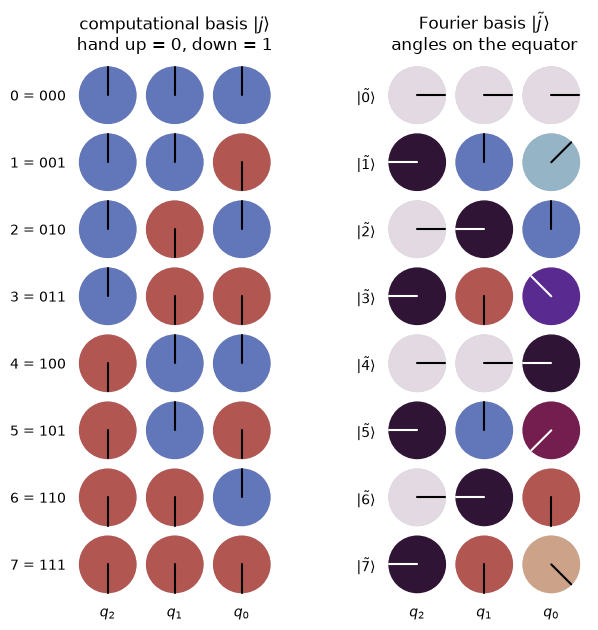

In [ ]:
show_bases(3)

In the computational basis a measurement reads $j$ directly. In the Fourier basis all eight outcomes are equally likely, since $j$ is hidden in the
phases. To read it, rotate back with $\mathrm{QFT}^\dagger$ and then measure, the same as measuring in the $X$ basis with $H$ (02, 4.2).

### 1.3 Writing a number into the angles yourself

**Your turn.** Build $|\tilde 5\rangle$ without the QFT. Use the table: $H$ on every qubit, then on qubit $m$ the phase gate
`qc.p(2 * np.pi * 2**m * j / 2**n, m)`.

1. Check that you got the same state as `qft(3)` applied to $|5\rangle$: `Statevector(qc).equiv(Statevector(reference))`.
2. Add `qft(3).inverse()`, measure and look at the counts.
3. Try $j = 6$ and $j = 1$. Remember this circuit, you will see it again in 2.1.

In [ ]:
n, j = 3, 5

reference = QuantumCircuit(n)
reference.x([0, 2])                    # |5> = |101>
reference.compose(qft(n), inplace=True)

# qc = QuantumCircuit(n)
# H on all qubits, then qc.p(...) on qubit m
# print(Statevector(qc).equiv(Statevector(reference)))
# qc.compose(qft(n).inverse(), inplace=True)
# qc.measure_all()
# print(run(qc))

<details>
<summary>Solution</summary>

```python
n, j = 3, 5

reference = QuantumCircuit(n)
reference.x([0, 2])                    # |5> = |101>
reference.compose(qft(n), inplace=True)

qc = QuantumCircuit(n)
qc.h(range(n))
for m in range(n):
    qc.p(2 * np.pi * 2**m * j / 2**n, m)
print('same state as QFT|5>:', Statevector(qc).equiv(Statevector(reference)))

qc.compose(qft(n).inverse(), inplace=True)
qc.measure_all()
print(run(qc))                         # {'101': 4096}
qc.draw('mpl')
```

</details>

## 2. Quantum phase estimation

### 2.1 From the Fourier state to QPE

In 1.3 you wrote $j$ into the angles with phase gates and read it out with $\mathrm{QFT}^\dagger$. QPE does exactly the same, except that the angles
come from an unknown unitary $U$. If $|u\rangle$ is an eigenstate, $U|u\rangle = e^{2\pi i\varphi}|u\rangle$, phase kickback (05, 2.1) turns the
control qubit by $\varphi$:

$$\frac{|0\rangle + |1\rangle}{\sqrt2}\,|u\rangle \;\xrightarrow{\ \text{controlled } U\ }\; \frac{|0\rangle + e^{2\pi i\varphi}|1\rangle}{\sqrt2}\,|u\rangle$$

and a controlled $U^{2^m}$ turns it by $2^m\varphi$. These are exactly the angles of the Fourier state from 1.2 with $j = 2^t\varphi$:

| step | control register ($t$ qubits) |
|---|---|
| 1. $H$ on every control qubit | $\vert{+}\cdots{+}\rangle = \vert\tilde 0\rangle$ |
| 2. $q_m$ controls $U^{2^m}$ | $q_m$ turned by $2^m\varphi$: the Fourier state $\vert\widetilde{2^t\varphi}\rangle$ |
| 3. $\mathrm{QFT}^\dagger$ | $\vert 2^t\varphi\rangle$ |
| 4. measure | $y = 2^t\varphi$, so $\varphi = y/2^t$ |

**Kickback writes $\varphi$ in the Fourier basis, $\mathrm{QFT}^\dagger$ translates it into bits.** The target register is not changed at all.

### 2.2 An exact phase

**Your turn.** Estimate the phase of $U = P(2\pi\varphi)$ with $\varphi = 5/8$. Its eigenstate is $|1\rangle$. Use $t = 3$ control qubits $q_0, q_1, q_2$
and the target $q_3$:

1. $X$ on $q_3$ (the eigenstate)
2. $H$ on $q_0, q_1, q_2$
3. from $q_m$ the controlled $U^{2^m}$. For a phase gate this is again a phase gate with a bigger angle: `qc.cp(2 * np.pi * phi * 2**m, m, 3)`
4. `qc.compose(qft(3).inverse(), range(3), inplace=True)`
5. measure $q_0, q_1, q_2$

Compare it with your circuit from 1.3: what is the only difference? Then fill in the table for other gates:

| gate | $T$ | $S$ | $Z$ | $P(2\pi\cdot 3/8)$ | $P(2\pi\cdot 5/8)$ |
|---|:-:|:-:|:-:|:-:|:-:|
| $\varphi$ | 1/8 | | | | 5/8 |
| measured $y$ | | | | | |

The key is $y$ directly, do not reverse it: $q_0$ has weight 1. The textbook draws the most significant qubit on top, Qiskit draws $q_0$ on top.

In [ ]:
phi = 5 / 8
t = 3

# qc = QuantumCircuit(t + 1, t)
# ...
# counts = run(qc)
# print(counts)

<details>
<summary>Solution</summary>

```python
phi = 5 / 8
t = 3

qc = QuantumCircuit(t + 1, t)
qc.x(t)
qc.h(range(t))
for m in range(t):
    qc.cp(2 * np.pi * phi * 2**m, m, t)
qc.compose(qft(t).inverse(), range(t), inplace=True)
qc.measure(range(t), range(t))

counts = run(qc)
y = int(max(counts, key=counts.get), 2)
print(counts, f'-> phi = {y}/{2**t}')
qc.draw('mpl')
```

</details>

Here is what happened inside the control register, step by step. The middle panel is row 5 of the table in 1.2. Change `phi` to see
another row.

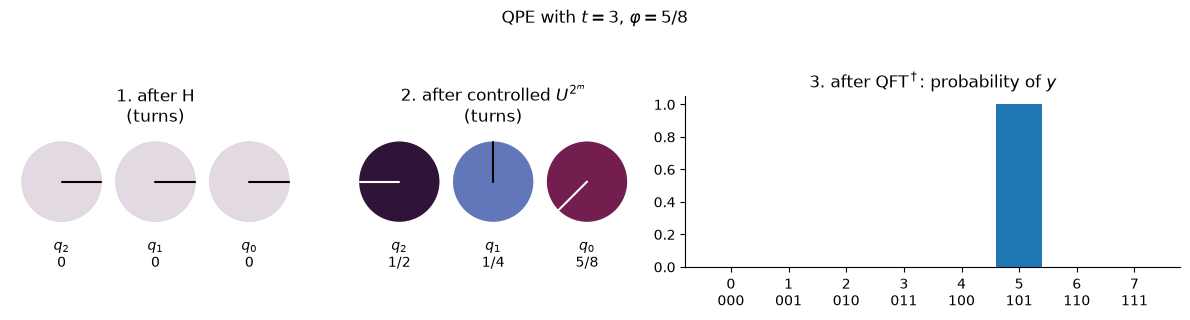

In [ ]:
show_qpe_stages(phi=5 / 8, t=3)

### 2.3 A real eigenvalue problem: a spin in a magnetic field

So far the answer was hidden in the angle of the gate, and the eigenstate was simply $|1\rangle$. Now the eigenvectors are not basis states.

A spin in a magnetic field tilted from the $z$ axis by an angle $\beta$ has the Hamiltonian

$$H = \cos\beta\; Z + \sin\beta\; X$$

with the energies $E = \pm 1$. The eigenstates are the spin pointing along the field, $|u_+\rangle = R_y(\beta)|0\rangle$, and against it,
$|u_-\rangle = R_y(\beta)|1\rangle$. The time evolution $U = e^{iH\tau}$ has the eigenvalues $e^{iE\tau}$, so the phase is $\varphi = E\tau/2\pi$.
QPE measures the energy.

We choose $\tau = 2\pi\cdot 3/16$. Then $\varphi_+ = 3/16$ and $\varphi_- = -3/16 \equiv 13/16$, and $t = 4$ is exact:

| result | $y = 3$ | $y = 13$ |
|---|:-:|:-:|
| energy | $E = +1$ | $E = -1$ |
| state | along the field | against the field |

For a general matrix we use `qpe` from 05, 5.2. It takes $U$ as a NumPy matrix and a small circuit `prepare` for the system register.

U =
 [[ 0.383+0.462j -0.   +0.8j  ]
 [ 0.   +0.8j    0.383-0.462j]]
phases from NumPy, in units of 1/16: [ 3. 13.]


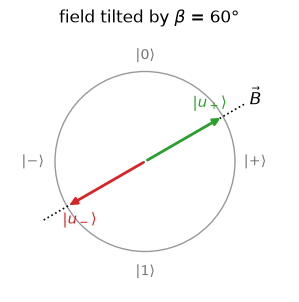

In [ ]:
def qpe(U: np.ndarray, t: int, prepare: QuantumCircuit, measure: bool = True) -> QuantumCircuit:
    # Control register q_0 ... q_{t-1}, q_m controls U^(2^m); the system is on the remaining qubits
    n = prepare.num_qubits
    system = list(range(t, t + n))
    qc = QuantumCircuit(t + n, t)
    qc.compose(prepare, system, inplace=True)
    qc.h(range(t))
    for m in range(t):
        power = UnitaryGate(np.linalg.matrix_power(U, 2**m), label=f'U^{2**m}').control(1)
        qc.append(power, [m] + system)
    qc.compose(qft(t).inverse(), range(t), inplace=True)
    if measure:
        qc.measure(range(t), range(t))
    return qc


X = np.array([[0, 1], [1, 0]])
Z = np.array([[1, 0], [0, -1]])

beta = np.pi / 3                       # the field is tilted by 60 degrees
tau = 2 * np.pi * 3 / 16
H_spin = np.cos(beta) * Z + np.sin(beta) * X
U = expm(1j * tau * H_spin)

print('U =\n', np.round(U, 3))
print('phases from NumPy, in units of 1/16:', np.sort(np.angle(np.linalg.eigvals(U)) / (2 * np.pi) % 1 * 16))
show_field(beta)

**Your turn.** Prepare the spin along the field, `prepare.ry(beta, 0)`, and run `qpe(U, 4, prepare)`. You should get one result only. Then
prepare the spin against the field ($X$ first, then `ry`). Finally start from plain $|0\rangle$, the spin pointing up. What do you get now,
and with which probabilities? (Hint: $|0\rangle = \cos\frac\beta2|u_+\rangle - \sin\frac\beta2|u_-\rangle$.)

In [ ]:
t = 4

# prepare = QuantumCircuit(1)
# prepare.ry(beta, 0)
# print(run(qpe(U, t, prepare)))

<details>
<summary>Solution</summary>

```python
t = 4

along = QuantumCircuit(1)
along.ry(beta, 0)
print('along the field  :', run(qpe(U, t, along)))          # only 0011 = 3

against = QuantumCircuit(1)
against.x(0)
against.ry(beta, 0)
print('against the field:', run(qpe(U, t, against)))        # only 1101 = 13

print('spin up |0>      :', run(qpe(U, t, QuantumCircuit(1))))   # 3 and 13, cos^2(30°) = 0.75 : 0.25
```

</details>

### 2.4 Close to an eigenstate

In practice we never know the eigenstate exactly. If we did, we could usually compute the eigenvalue without a quantum computer. What we have is a
**guess**, for example a field direction that is off by a small angle $\delta$: $|\psi\rangle = R_y(\beta + \delta)|0\rangle$. In the
eigenbasis

$$|\psi\rangle = \cos\frac{\delta}{2}\,|u_+\rangle + \sin\frac{\delta}{2}\,|u_-\rangle$$

and by linearity QPE gives $y = 3$ with probability $\cos^2\frac\delta2$ and $y = 13$ with probability $\sin^2\frac\delta2$. Two things to notice:

* **The answer does not get blurred.** A bad guess does not move the peak away from $3/16$. It only makes the wrong answer $13/16$ appear
  sometimes, and we can tell the two apart.
* For $\delta = 0.3$ (17°) the guess is still right in 98 % of the runs. A good guess is enough.

This is how QPE is meant to be used in quantum chemistry. A classical method gives an approximate ground state, and QPE then finds the exact ground state
energy with a probability equal to the overlap.

**Your turn.** Prepare the guess with $\delta = 0.3$, run `qpe(U, 4, prepare)` and compare the fraction of `'0011'` with $\cos^2(\delta/2)$. Then try
$\delta = 0.1,\ 1,\ \pi/2,\ \pi$. When are the two answers equally likely, and what does the guess look like then?

In [ ]:
t = 4
delta = 0.3

# prepare = QuantumCircuit(1)
# ...
# counts = run(qpe(U, t, prepare))

<details>
<summary>Solution</summary>

```python
t = 4
delta = 0.3

prepare = QuantumCircuit(1)
prepare.ry(beta + delta, 0)
counts = run(qpe(U, t, prepare))

print(counts)
print(f'P(y = 3) = {counts.get("0011", 0) / shots:.3f}, cos^2(delta/2) = {np.cos(delta / 2)**2:.3f}')
```

</details>

The whole curve, one QPE run of 4096 shots for each point:

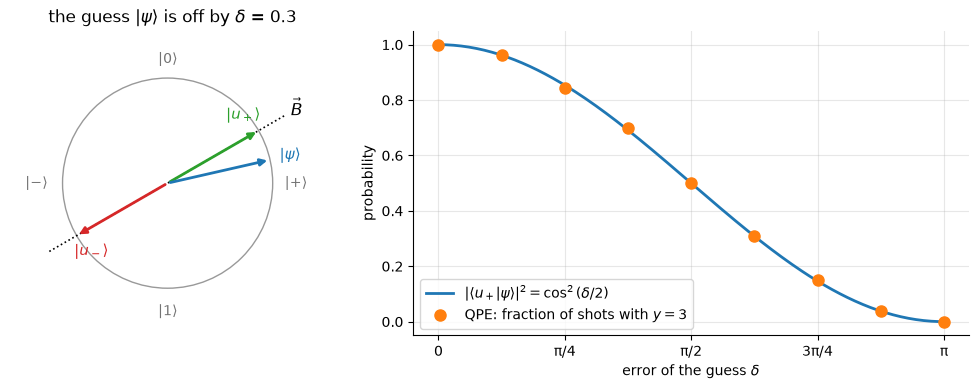

In [ ]:
deltas = np.linspace(0, np.pi, 9)
p_right = []
for delta in deltas:
    prepare = QuantumCircuit(1)
    prepare.ry(beta + delta, 0)
    p_right.append(run(qpe(U, 4, prepare)).get('0011', 0) / shots)

show_near_eigenstate(beta, deltas, p_right)

**QPE also corrects the guess.** After the measurement the spin is no longer the guess $|\psi\rangle$. For $y = 3$ it is exactly along the field. The
helper `system_after` gives the state of the spin for a chosen result $y$, computed from the state just before the measurement:

In [ ]:
delta = 0.3
eigenstate = QuantumCircuit(1)
eigenstate.ry(beta, 0)
u_plus = Statevector(eigenstate)                   # along the field
eigenstate = QuantumCircuit(1)
eigenstate.x(0)
eigenstate.ry(beta, 0)
u_minus = Statevector(eigenstate)                  # against the field

prepare = QuantumCircuit(1)
prepare.ry(beta + delta, 0)
print(f'before QPE: overlap of the guess with |u+> = {state_fidelity(Statevector(prepare), u_plus):.3f}')

state = Statevector(qpe(U, 4, prepare, measure=False))
for y in [3, 13]:
    spin = system_after(state, y, t=4)
    print(f'after y = {y:2d}: overlap with |u+> = {state_fidelity(spin, u_plus):.3f}, with |u-> = {state_fidelity(spin, u_minus):.3f}')

before QPE: overlap of the guess with |u+> = 0.978
after y =  3: overlap with |u+> = 1.000, with |u-> = 0.000
after y = 13: overlap with |u+> = 0.000, with |u-> = 1.000


### 2.5 A phase that does not fit into $t$ bits

The other way to get an uncertain answer: the input *is* an eigenstate, but $2^t\varphi$ is not an integer. Take $\varphi = 1/3 = 0.010101\ldots_2$. No
$y$ is exactly right, and the probability spreads around the nearest values $y \approx 2^t/3$.

**Your turn.** Run `qpe(U_third, t, one)` for $t = 3, 5, 8$. For each $t$ find the most frequent $y$, compute $y/2^t$ and its distance from $1/3$.
How does the probability of the best $y$ change?

In [ ]:
phi = 1 / 3
U_third = np.diag([1, np.exp(2j * np.pi * phi)])
one = QuantumCircuit(1)
one.x(0)

# for t in [3, 5, 8]:
#     counts = run(qpe(U_third, t, one))
#     ...

<details>
<summary>Solution</summary>

```python
phi = 1 / 3
U_third = np.diag([1, np.exp(2j * np.pi * phi)])
one = QuantumCircuit(1)
one.x(0)

for t in [3, 5, 8]:
    counts = run(qpe(U_third, t, one))
    y = int(max(counts, key=counts.get), 2)
    print(f't = {t}: y = {y:3d}, y/2^t = {y / 2**t:.4f}, error {abs(y / 2**t - phi):.4f}, P = {counts[f"{y:0{t}b}"] / shots:.2f}')
```

</details>

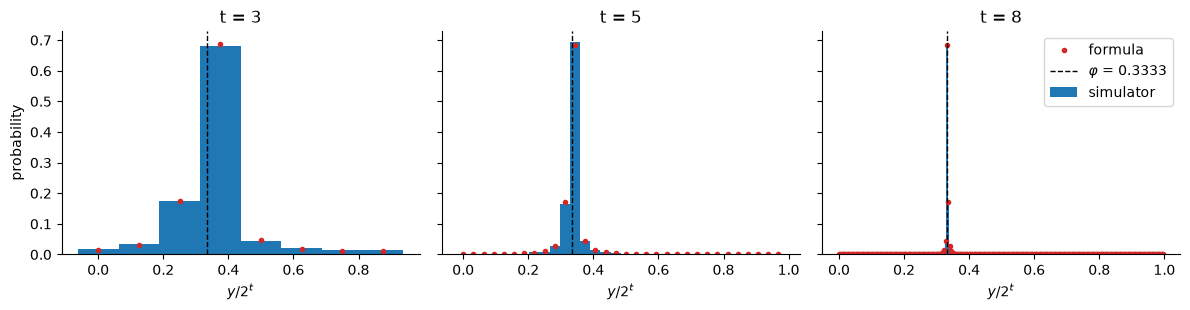

In [ ]:
phi = 1 / 3
U_third = np.diag([1, np.exp(2j * np.pi * phi)])
one = QuantumCircuit(1)
one.x(0)

show_qpe_histograms({t: run(qpe(U_third, t, one)) for t in [3, 5, 8]}, phi)

Two kinds of "not sure", side by side:

| | input | what you see | how to improve |
|---|---|---|---|
| 2.4 | not an eigenstate | a few **sharp** peaks at the exact phases of the eigenstates it contains | a better guess |
| 2.5 | eigenstate, $2^t\varphi$ not an integer | **one blurred** peak around $\varphi$, the best $y$ still has probability above $4/\pi^2 \approx 0.4$ | more control qubits |

### 2.6 What QPE costs

| | runs | applications of $U$ for $t$ bits |
|---|:-:|:-:|
| interferometer and statistics (05, 1.3) | $\approx 4^t$ | $\approx 4^t$ |
| QPE | 1 | $1 + 2 + \dots + 2^{t-1} = 2^t - 1$ |

The $\mathrm{QFT}^\dagger$ is cheap, $O(t^2)$ gates. The expensive part is the controlled $U^{2^m}$, unless the powers have a shortcut. Quantum
counting and Shor's algorithm in 05 (sections 6 and 7) are this circuit with a particular $U$.

## 3. BB84: quantum key distribution

Alice wants to share a secret random key with Bob. She sends him single qubits (photons) over a quantum channel, and they also have a public, authenticated
classical channel. The eavesdropper is called Eve. The security does not come from a hard mathematical problem, it comes from the fact that
**measuring in the wrong basis disturbs the state**, so Eve leaves traces.

### 3.1 Four states, two bases

| basis | bit 0 | bit 1 |
|:-:|:-:|:-:|
| $Z$ | $\vert 0\rangle$ | $\vert 1\rangle$ |
| $X$ | $\vert +\rangle$ | $\vert -\rangle$ |

The $X$ basis is the Fourier basis of one qubit from 1.1, so the circuits are the ones you already know:

* **prepare** bit $a$ in basis $X$: $X^a$, then $H$
* **measure** in basis $X$: $H$, then a normal measurement (rotate back, then measure)

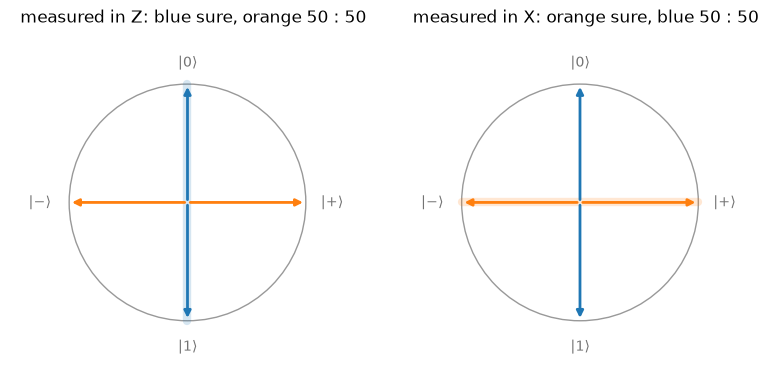

In [ ]:
show_bb84_states()

**Your turn.** Prepare each of the four states and measure it in $Z$ and in $X$, 1000 shots each, in a double loop over Alice's basis and bit and
Bob's basis. Which combinations give a certain result and which give 50 : 50? This is the table *Výsledek Bobova měření* from the textbook.

In [ ]:
# for alice_basis in ['Z', 'X']:
#     for bit in [0, 1]:
#         for bob_basis in ['Z', 'X']:
#             qc = QuantumCircuit(1, 1)
#             ...

<details>
<summary>Solution</summary>

```python
for alice_basis in ['Z', 'X']:
    for bit in [0, 1]:
        results = []
        for bob_basis in ['Z', 'X']:
            qc = QuantumCircuit(1, 1)
            if bit == 1:
                qc.x(0)
            if alice_basis == 'X':
                qc.h(0)                # Alice prepares
            if bob_basis == 'X':
                qc.h(0)                # Bob rotates back
            qc.measure(0, 0)
            results.append(f'{bob_basis}: {run(qc, shots=1000)}')
        print(f'bit {bit} in {alice_basis}  |  ' + '  |  '.join(results))
```

</details>

### 3.2 The protocol, on the example from the textbook

1. Alice picks a random bit $a_i$ and a random basis $\alpha_i$ for every photon and sends the state.
2. Bob picks a random basis $\beta_i$ and measures, which gives $b_i$.
3. Over the public channel they announce **only the bases**. Where $\alpha_i \ne \beta_i$ they throw the bit away. The rest is the *sifted key*.

In a circuit every photon is one qubit, all of them in one circuit. A single run (one shot) is one run of the protocol, and `run_once`
returns the bits of every classical register, $q_0$ first:

In [ ]:
def run_once(qc: QuantumCircuit) -> dict:
    # One shot; {register name: array of bits, qubit 0 first}
    key = list(sim.run(qc, shots=1).result().get_counts())[0]
    return {reg.name: np.array([int(b) for b in reversed(bits)]) for reg, bits in zip(qc.cregs, reversed(key.split()))}


# Table "Příklad protokolu BB84 bez odposlechu" from the textbook, 12 photons
alice_bits = [0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0]
alice_bases = 'XXZXXZZZZZXX'
bob_bases = 'ZZXXXZXXZXXX'

**Your turn.**

1. Build the circuit with 12 qubits and a classical register `ClassicalRegister(12, 'bob')`. Alice: `x` where her bit is 1, `h` where her basis is X.
   Then `qc.barrier()`, which stands for the channel. Bob: `h` where his basis is X, then measure everything.
2. Run it once, `bob_bits = run_once(qc)['bob']`.
3. Sift: keep the positions where the bases agree. Compare the keys of Alice and Bob, the textbook gets $010010$.

In [ ]:
n = len(alice_bits)

# qc = QuantumCircuit(QuantumRegister(n, 'q'), ClassicalRegister(n, 'bob'))
# ...
# bob_bits = run_once(qc)['bob']
# keep = [i for i in range(n) if ...]
# print('Alice:', ..., 'Bob:', ...)

<details>
<summary>Solution</summary>

```python
n = len(alice_bits)

qc = QuantumCircuit(QuantumRegister(n, 'q'), ClassicalRegister(n, 'bob'))
for i in range(n):                     # Alice
    if alice_bits[i] == 1:
        qc.x(i)
    if alice_bases[i] == 'X':
        qc.h(i)
qc.barrier()                           # the channel
for i in range(n):                     # Bob
    if bob_bases[i] == 'X':
        qc.h(i)
qc.measure(range(n), range(n))

bob_bits = run_once(qc)['bob']
keep = [i for i in range(n) if alice_bases[i] == bob_bases[i]]
print('Alice:', ''.join(str(alice_bits[i]) for i in keep))
print('Bob:  ', ''.join(str(bob_bits[i]) for i in keep))
qc.draw('mpl', fold=-1)
```

</details>

The same run as a table. Grey columns are thrown away, and Bob's bits there are random, run it again to see them change. The white columns are always the
same.

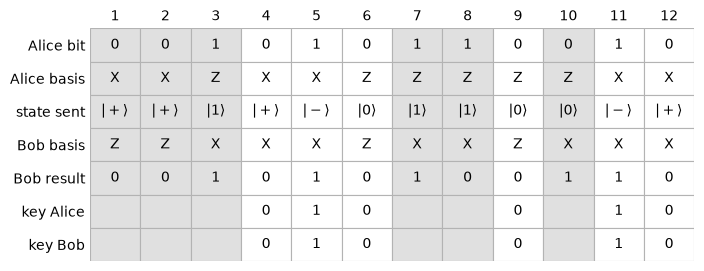

sifted key: 6 bits, 0 of them differ


In [ ]:
qc = QuantumCircuit(QuantumRegister(12, 'q'), ClassicalRegister(12, 'bob'))
for i in range(12):
    if alice_bits[i] == 1:
        qc.x(i)
    if alice_bases[i] == 'X':
        qc.h(i)
    if bob_bases[i] == 'X':
        qc.h(i)
qc.measure(range(12), range(12))

show_protocol(alice_bits, alice_bases, bob_bases, run_once(qc)['bob'])

### 3.3 Eve: intercept and resend

Eve catches every photon, measures it in a random basis $\varepsilon_i$ and sends Bob the state she measured. In the circuit this is very short:
after a measurement the qubit already *is* $|0\rangle$ or $|1\rangle$, so she only has to rotate back:

* basis $Z$: measure
* basis $X$: $H$, measure, $H$

If she guessed the basis right, she learns the bit and Bob gets the original state. If she guessed wrong, Bob gets a state of the other basis, and even
in the right basis he measures a random bit.

**Your turn.** Put Eve into your circuit from 3.2, between Alice and Bob, with Eve's bases from the textbook (below). Give her a classical register of her own,
`ClassicalRegister(12, 'eve')`, so that `run_once(qc)` returns both `'bob'` and `'eve'`. How many bits of the sifted key differ? Run it a few times.

In [ ]:
eve_bases = 'XZXXXZZXXXZZ'            # from the table "s útokem zachycením a přeposláním"
n = len(alice_bits)

# qc = QuantumCircuit(QuantumRegister(n, 'q'), ClassicalRegister(n, 'bob'), ClassicalRegister(n, 'eve'))
# Alice ...
# Eve: for each qubit h (if X), qc.measure(i, n + i), h (if X)
# Bob ...
# result = run_once(qc)

<details>
<summary>Solution</summary>

```python
eve_bases = 'XZXXXZZXXXZZ'            # from the table "s útokem zachycením a přeposláním"
n = len(alice_bits)

bob, eve = ClassicalRegister(n, 'bob'), ClassicalRegister(n, 'eve')
qc = QuantumCircuit(QuantumRegister(n, 'q'), bob, eve)
for i in range(n):                     # Alice
    if alice_bits[i] == 1:
        qc.x(i)
    if alice_bases[i] == 'X':
        qc.h(i)
qc.barrier()
for i in range(n):                     # Eve measures and resends
    if eve_bases[i] == 'X':
        qc.h(i)
    qc.measure(i, eve[i])
    if eve_bases[i] == 'X':
        qc.h(i)
qc.barrier()
for i in range(n):                     # Bob
    if bob_bases[i] == 'X':
        qc.h(i)
qc.measure(range(n), bob)

result = run_once(qc)
show_protocol(alice_bits, alice_bases, bob_bases, result['bob'], eve_bases, result['eve'])
```

</details>

### 3.4 The statistics: QBER = 1/4

The *quantum bit error rate* (QBER) is the fraction of the sifted key where Alice and Bob differ. On a sifted position Eve picks the wrong basis with
probability $\frac12$, and then Bob's bit is wrong with probability $\frac12$:

$$\mathrm{QBER} = \frac12\cdot\frac12 = \frac14$$

A dozen photons do not show that, many do. Below is the general version of your circuits. Eve's basis `'-'` means she leaves the photon alone,
and `errors` adds a Pauli gate in the fibre (3.5). The photons are independent, so `bb84` sends them in blocks of 200, which the simulator
handles fastest.

In [ ]:
def bb84_circuit(alice_bits, alice_bases, bob_bases, eve_bases=None, errors=None) -> QuantumCircuit:
    # One qubit per photon. eve_bases: 'Z', 'X' or '-' per photon; errors: 'I', 'X', 'Y' or 'Z' per photon
    n = len(alice_bits)
    bob, eve = ClassicalRegister(n, 'bob'), ClassicalRegister(n, 'eve')
    qc = QuantumCircuit(QuantumRegister(n, 'q'), bob, eve)
    for i in range(n):                                   # Alice
        if alice_bits[i] == 1:
            qc.x(i)
        if alice_bases[i] == 'X':
            qc.h(i)
    for i in range(n if eve_bases is not None else 0):   # Eve
        if eve_bases[i] in 'ZX':
            if eve_bases[i] == 'X':
                qc.h(i)
            qc.measure(i, eve[i])
            if eve_bases[i] == 'X':
                qc.h(i)
    for i in range(n if errors is not None else 0):      # noise in the fibre
        if errors[i] != 'I':
            {'X': qc.x, 'Y': qc.y, 'Z': qc.z}[errors[i]](i)
    for i in range(n):                                   # Bob
        if bob_bases[i] == 'X':
            qc.h(i)
    qc.measure(range(n), bob)
    return qc


def bb84(n: int, eve_fraction: float = 0.0, p_noise: float = 0.0, block: int = 200):
    # Random bits and bases; Eve intercepts a fraction of the photons, the fibre applies a random Pauli with probability p_noise
    alice_bits = rng.integers(0, 2, n)
    alice_bases = rng.choice(['Z', 'X'], n)
    bob_bases = rng.choice(['Z', 'X'], n)
    eve_bases = np.where(rng.random(n) < eve_fraction, rng.choice(['Z', 'X'], n), '-')
    errors = np.where(rng.random(n) < p_noise, rng.choice(['X', 'Y', 'Z'], n), 'I')
    bob_bits = np.concatenate([
        run_once(bb84_circuit(alice_bits[s], alice_bases[s], bob_bases[s], eve_bases[s], errors[s]))['bob']
        for s in (slice(start, start + block) for start in range(0, n, block))])
    keep = alice_bases == bob_bases
    return alice_bits[keep], bob_bits[keep]


def qber(key_alice, key_bob) -> float:
    return float(np.mean(key_alice != key_bob))


key_alice, key_bob = bb84(1000)
print(f'no Eve:   sifted {len(key_alice)} of 1000 bits, QBER = {qber(key_alice, key_bob):.3f}')
key_alice, key_bob = bb84(1000, eve_fraction=1)
print(f'full Eve: sifted {len(key_alice)} of 1000 bits, QBER = {qber(key_alice, key_bob):.3f}')

no Eve:   sifted 520 of 1000 bits, QBER = 0.000
full Eve: sifted 516 of 1000 bits, QBER = 0.229


The textbook exercise: QBER for $n = 10^2, 10^3, 10^4$ photons, five runs each. The spread shrinks like $1/\sqrt n$. (The cell runs for a few
seconds.)

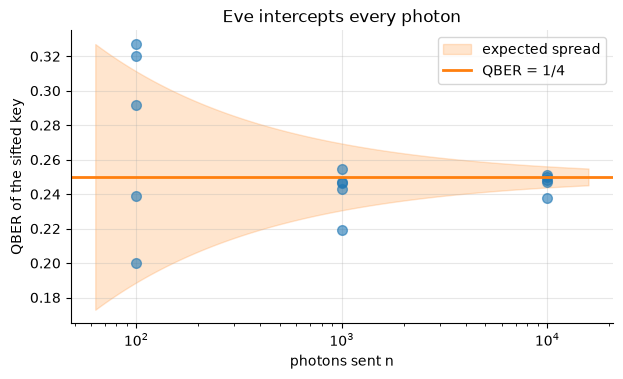

In [ ]:
results = {n: [qber(*bb84(n, eve_fraction=1)) for _ in range(5)] for n in [100, 1000, 10000]}
show_qber_vs_n(results)

In a real run Alice and Bob do not compare the whole key, that would reveal it. They publish a random sample of $k$ sifted bits and throw those away.
Against the full attack every compared bit agrees with probability $3/4$, so Eve stays hidden with probability $(3/4)^k$.

### 3.5 A noisy channel

A real fibre is not perfect either. Our model: with probability $p$ the photon gets a random Pauli gate, $X$, $Y$ or $Z$, each with probability $p/3$.
This is the depolarising channel, the same as `depolarizing_error` in the noise model of 05, 5.6.

**Your turn.** First on paper: which of $X$, $Y$, $Z$ flips a bit sent in the $Z$ basis ($|0\rangle, |1\rangle$), and which flips a bit sent in the $X$ basis
($|+\rangle, |-\rangle$)? From that, what QBER does the noise give? Then check it with `bb84(4000, p_noise=0.15)`.
Second: Eve intercepts only a fraction $f$ of the photons. What QBER does she cause?

In [ ]:
# key_alice, key_bob = bb84(4000, p_noise=0.15)
# print(qber(key_alice, key_bob))

<details>
<summary>Solution</summary>

```python
# X flips |0>,|1> but leaves |+>,|-> alone (up to a sign); Z the other way round; Y flips both.
# Every basis is flipped by 2 of the 3 Paulis: QBER = 2p/3.  Eve on a fraction f: QBER = f/4.
key_alice, key_bob = bb84(4000, p_noise=0.15)
print(f'noise p = 0.15: QBER = {qber(key_alice, key_bob):.3f}, 2p/3 = {2 * 0.15 / 3:.3f}')
key_alice, key_bob = bb84(4000, eve_fraction=0.4)
print(f'Eve f = 0.4:    QBER = {qber(key_alice, key_bob):.3f}, f/4  = {0.4 / 4:.3f}')
```

</details>

Both sources of errors together, 3000 photons per point. (The cell runs for a few seconds.)

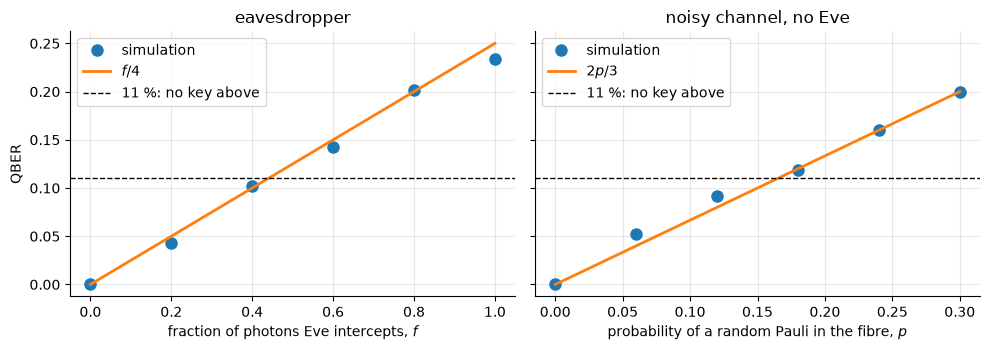

In [ ]:
fs = np.linspace(0, 1, 6)
ps = np.linspace(0, 0.3, 6)
qber_eve = [qber(*bb84(3000, eve_fraction=f)) for f in fs]
qber_noise = [qber(*bb84(3000, p_noise=p)) for p in ps]

show_qber_sources(fs, qber_eve, ps, qber_noise)

**Alice and Bob cannot tell noise from Eve.** An error is an error, so to be safe they have to assume that *all* of them come from Eve. A noisy channel
and a careful Eve who listens only to some of the photons look exactly the same.

### 3.6 Is the key still usable?

The sifted key is not the final key. Alice and Bob correct the differences (which reveals some information) and then shorten the key by hashing
(*privacy amplification*) so that Eve knows almost nothing about the result. According to Shor and Preskill, the number of secret bits per sifted bit is

$$r = 1 - 2H(Q), \qquad H(Q) = -Q\log_2 Q - (1-Q)\log_2(1-Q)$$

which drops to zero at $Q \approx 11\,\%$. Above that, no key is produced and the protocol is aborted.

**Your turn.** Compute $r$ for a fibre with $p = 0.03$, for $Q = 0.05$, and for the full attack $Q = 1/4$. How many sifted bits do Alice and Bob have to compare so
that the full attack goes unnoticed with probability below $10^{-6}$?

In [ ]:
# def entropy(q):
#     ...
# for Q in [...]:
#     print(Q, 1 - 2 * entropy(Q))

<details>
<summary>Solution</summary>

```python
def entropy(q):
    return -q * np.log2(q) - (1 - q) * np.log2(1 - q)


for label, Q in [('fibre p = 0.03', 2 * 0.03 / 3), ('Q = 0.05', 0.05), ('full Eve', 0.25)]:
    print(f'{label:15s} Q = {Q:.3f}: r = {1 - 2 * entropy(Q):+.3f}')

k = int(np.ceil(np.log(1e-6) / np.log(3 / 4)))
print(f'compare k = {k} bits: (3/4)^k = {0.75**k:.1e}')
```

</details>

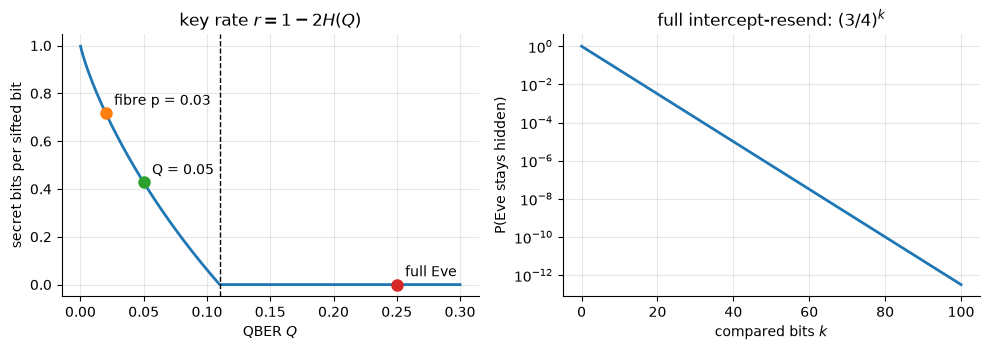

In [ ]:
show_key_rate({'fibre p = 0.03': 0.02, 'Q = 0.05': 0.05, 'full Eve': 0.25})

### 3.7 Why can't Eve simply copy the photon?

If Eve could make a copy, she would send the original to Bob untouched and measure her copy only after the bases are announced. No error, no trace.
The no-cloning theorem forbids this for an unknown state. The obvious copier, a CNOT onto a fresh $|0\rangle$, works for one basis only.

**Your turn.** For each of the four BB84 states $|\psi\rangle$ on $q_0$, apply `qc.cx(0, 1)` with $q_1$ in $|0\rangle$ and compare the result with the
perfect copy $|\psi\rangle|\psi\rangle$, using `Statevector(...).equiv(...)`. For which states does it work? What do you get for $|+\rangle$ instead? Look at
it with `Statevector(qc).draw('latex')`.

In [ ]:
# for name, bit, basis in [('|0>', 0, 'Z'), ('|1>', 1, 'Z'), ('|+>', 0, 'X'), ('|->', 1, 'X')]:
#     one = QuantumCircuit(1)       # the state |psi>
#     ...
#     copier = QuantumCircuit(2)    # |psi> on q_0, then cx(0, 1)
#     ...
#     perfect = QuantumCircuit(2)   # |psi> on both qubits
#     ...

<details>
<summary>Solution</summary>

```python
for name, bit, basis in [('|0>', 0, 'Z'), ('|1>', 1, 'Z'), ('|+>', 0, 'X'), ('|->', 1, 'X')]:
    psi = QuantumCircuit(1)
    if bit == 1:
        psi.x(0)
    if basis == 'X':
        psi.h(0)

    copier = QuantumCircuit(2)
    copier.compose(psi, [0], inplace=True)
    copier.cx(0, 1)

    perfect = QuantumCircuit(2)
    perfect.compose(psi, [0], inplace=True)
    perfect.compose(psi, [1], inplace=True)

    print(f'{name}: copied = {Statevector(copier).equiv(Statevector(perfect))}')

plus_copier = QuantumCircuit(2)
plus_copier.h(0)
plus_copier.cx(0, 1)
Statevector(plus_copier).draw('latex')           # (|00> + |11>)/sqrt 2, a Bell state, not |++>
```

</details>

The CNOT copies $|0\rangle$ and $|1\rangle$ and turns $|+\rangle$ into the Bell state $(|00\rangle + |11\rangle)/\sqrt2$, not into $|{+}{+}\rangle$. A copier
built for the $X$ basis ($H$ on both qubits around the CNOT) fails on the $Z$ basis. Eve does not know which basis each photon uses, and no single
operation copies both. (The textbook proves this for any unitary, also with an ancilla.)

**Questions**

- In 1.2, which qubit of $|\tilde j\rangle$ tells you whether $j$ is even or odd?
- In 2.2, why is the controlled $U^{2^m}$ for $U = P(\alpha)$ just $P(2^m\alpha)$? Why is that not possible for a general $U$?
- In 2.3, what does QPE give with $t = 3$ instead of 4? And with $\tau = 2\pi/3$?
- In 2.4, find a guess $|\psi\rangle$ for which $y = 3$ and $y = 13$ are equally likely. Where does it point on the Bloch sphere?
- After a QPE run gave $y = 3$, you run QPE again on the same spin. What do you get, and why?
- In BB84, why may Alice and Bob announce the bases publicly, but only *after* Bob has measured?
- Eve measures every photon in the $Z$ basis only. What QBER does she cause, and how much of the key does she learn?
- With a fibre of $p = 0.1$, can Alice and Bob still make a key? And with $p = 0.2$?
- Why must the classical channel be authenticated, although it does not have to be secret?